***Classification***

In [5]:
!apt-get -qq update > /dev/null && apt-get -qq install -y texlive-latex-extra texlive-fonts-recommended cm-super dvipng > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [6]:
import pandas as pd, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt, os
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
os.makedirs("figures", exist_ok=True)

df = pd.read_csv("outlier_checked_data.csv")
result_order = ["Extinguished early", "Partially burned", "Completely burned"]
df["fire_result"] = pd.Categorical(df["fire_result"], categories=result_order, ordered=True)
print(df.shape)
print("Missing values:", df.isna().sum().sum())

(31845, 19)
Missing values: 0


***1. Target and Features***

In [7]:
# 1a. target: fire_result ("Fire Outcome"), 3 classes
# fire_severity is a 1:1 re-encoding of fire_result (verified by crosstab below) -> dropped to avoid leakage
print(pd.crosstab(df["fire_result"], df["fire_severity"]))

fire_severity           0     1     2
fire_result                          
Extinguished early  29349     0     0
Partially burned        0  1484     0
Completely burned       0     0  1012


In [8]:
# 1b. group rare categories (< 1% of rows) into "Other", same logic as the SMOTENC step in outliers_pca.ipynb,
# applied here to both fire_type and fire_cause since both are high-cardinality
def group_rare(s, threshold=0.01):
    counts = s.value_counts(normalize=True)
    rare = counts[counts < threshold].index
    return s.where(~s.isin(rare), "Other")

df["fire_type_grouped"] = group_rare(df["fire_type"])
df["fire_cause_grouped"] = group_rare(df["fire_cause"])
print("fire_type:", df["fire_type"].nunique(), "->", df["fire_type_grouped"].nunique())
print("fire_cause:", df["fire_cause"].nunique(), "->", df["fire_cause_grouped"].nunique())

fire_type: 41 -> 12
fire_cause: 33 -> 8


In [9]:
# 1c. feature set
# - district excluded from the model: 31 distinct values, one-hot encoding it would add 30+ sparse
#   columns and risks overfitting on district-specific quirks rather than fire characteristics;
#   discussed as a trade-off in the report instead (district-level patterns were already explored
#   via PCA in outliers_pca.ipynb)
# - arrival_cat excluded: it is a discretized copy of arrival_min, so keeping both is redundant
# - iso_outlier kept as a 0/1 flag (engineered in outliers_pca.ipynb, not derived from the target)
numeric_features = ["foam_kg", "water_m3", "dry_powder_kg", "year", "arrival_min",
                     "dispatch_hour", "month", "human_deaths", "human_injured", "animal_deaths"]
categorical_features = ["fire_type_grouped", "fire_cause_grouped", "building_type", "region"]

X = df[numeric_features + categorical_features].copy()
X["iso_outlier"] = df["iso_outlier"].astype(int)
X = pd.get_dummies(X, columns=categorical_features)
y = df["fire_result"]

print("Features:", X.shape[1])
print(X.columns.tolist())

Features: 42
['foam_kg', 'water_m3', 'dry_powder_kg', 'year', 'arrival_min', 'dispatch_hour', 'month', 'human_deaths', 'human_injured', 'animal_deaths', 'iso_outlier', 'fire_type_grouped_Building', 'fire_type_grouped_Factory/workshop', 'fire_type_grouped_Forest/nursery', 'fire_type_grouped_Garbage', 'fire_type_grouped_Grass', 'fire_type_grouped_Other', 'fire_type_grouped_Reed bed', 'fire_type_grouped_Transformer', 'fire_type_grouped_Tree', 'fire_type_grouped_Vehicle', 'fire_type_grouped_Vineyard/garden', 'fire_type_grouped_Workplace', 'fire_cause_grouped_Cigarette/match', 'fire_cause_grouped_Electrical short circuit', 'fire_cause_grouped_Open fire', 'fire_cause_grouped_Other', 'fire_cause_grouped_Spark (chimney)', 'fire_cause_grouped_Spark (other)', 'fire_cause_grouped_Suspicious', 'fire_cause_grouped_To be determined by forestry', 'building_type_Bagdadi (timber-frame)', 'building_type_Masonry', 'building_type_Not applicable', 'building_type_Other', 'building_type_Prefabricated', 'buil

***2. Train / Validation / Test Split (60/20/20, stratified)***

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

print("Train:", len(X_train), " Val:", len(X_val), " Test:", len(X_test))
for name, split in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, dict((split.value_counts(normalize=True) * 100).round(1)))

Train: 19107  Val: 6369  Test: 6369
Train {'Extinguished early': np.float64(92.2), 'Partially burned': np.float64(4.7), 'Completely burned': np.float64(3.2)}
Val {'Extinguished early': np.float64(92.2), 'Partially burned': np.float64(4.7), 'Completely burned': np.float64(3.2)}
Test {'Extinguished early': np.float64(92.1), 'Partially burned': np.float64(4.7), 'Completely burned': np.float64(3.2)}


***3. Class Imbalance***

fire_result
Extinguished early    92.2
Partially burned       4.7
Completely burned      3.2
Name: proportion, dtype: float64


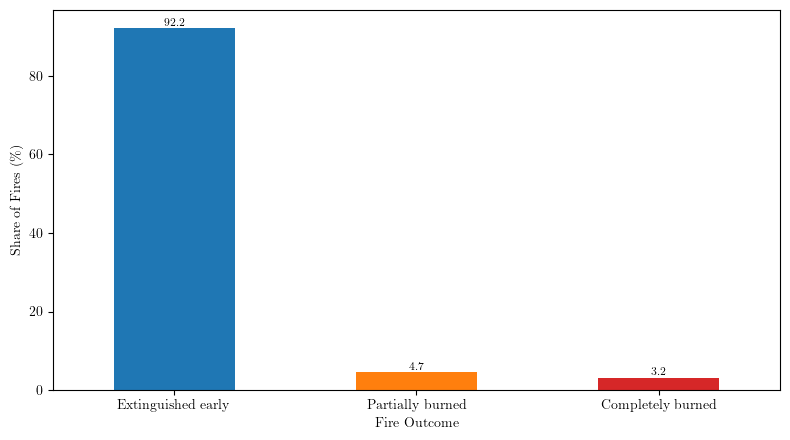

In [11]:
# 3a. class shares in the full data set
share = (y.value_counts(normalize=True).reindex(result_order) * 100)
print(share.round(1))

ax = share.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["tab:blue", "tab:orange", "tab:red"])
ax.set_xlabel("Fire Outcome"); ax.set_ylabel(r"Share of Fires (\%)")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=8)
plt.tight_layout()
plt.savefig("figures/class_imbalance.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# 3b. LaTeX (pgfplots) version of the class-imbalance figure, same helper as outliers_pca.ipynb
def bars_to_latex(data, path, xlabel, ylabel, colors, decimals=1):
    cats = [str(c) for c in data.index]
    ymax = float(np.ceil(data.values.max() * 1.15))
    L = ["{%", r"\begin{tikzpicture}", r"\begin{axis}[",
         r"  width=\columnwidth, height=0.62\columnwidth,",
         rf"  ybar, bar width=12pt, ymin=0, ymax={ymax:g},",
         r"  symbolic x coords={" + ",".join(cats) + "}, xtick=data,",
         r"  enlarge x limits=0.25,",
         r"  xlabel={" + xlabel + "}, ylabel={" + ylabel + "},",
         r"  tick label style={font=\scriptsize}, label style={font=\small},",
         r"  nodes near coords={\pgfmathprintnumber[fixed,fixed zerofill,precision="
             + str(decimals) + r"]{\pgfplotspointmeta}},",
         r"  every node near coord/.append style={font=\tiny},",
         "]"]
    r, g, b = [[int(round(x * 255)) for x in mpl.colors.to_rgb(c)] for c in colors][0], None, None
    coords = " ".join(f"({cat},{v:.{decimals}f})" for cat, v in zip(cats, data.values))
    rgb_list = [mpl.colors.to_rgb(c) for c in colors]
    addplots = []
    for cat, v, c in zip(cats, data.values, rgb_list):
        rr, gg, bb = [int(round(x * 255)) for x in c]
        addplots.append(rf"\addplot[fill={{rgb,255:red,{rr};green,{gg};blue,{bb}}}, draw=none] coordinates {{({cat},{v:.{decimals}f})}};")
    L += addplots
    L += [r"\end{axis}", r"\end{tikzpicture}%", "}"]
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(L))
    print("Saved:", path)

bars_to_latex(share, "figures/class_imbalance.tex", xlabel="Fire Outcome",
              ylabel=r"Share of Fires (\%)", colors=["tab:blue", "tab:orange", "tab:red"])

Saved: figures/class_imbalance.tex


***4. Model Training***

In [13]:
# 4a. Decision Tree: tune max_depth on the validation set (macro F1, the metric that weighs
# minority classes equally with the majority class)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

depths = [3, 4, 5, 6, 8, 10, 12, None]
dt_scores = []
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=42)
    clf.fit(X_train, y_train)
    f1 = f1_score(y_val, clf.predict(X_val), average="macro")
    dt_scores.append(f1)
    print(f"max_depth={d}: val macro F1={f1:.3f}")

best_depth = depths[int(np.argmax(dt_scores))]
print("\nBest max_depth:", best_depth)

max_depth=3: val macro F1=0.368
max_depth=4: val macro F1=0.426
max_depth=5: val macro F1=0.459
max_depth=6: val macro F1=0.460
max_depth=8: val macro F1=0.526
max_depth=10: val macro F1=0.508
max_depth=12: val macro F1=0.536
max_depth=None: val macro F1=0.527

Best max_depth: 12


In [14]:
# 4b. final Decision Tree, fit on train, evaluated later on the untouched test set
dt_model = DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=12, random_state=42)

In [15]:
# 4c. Random Forest: tune n_estimators and max_depth on the validation set
n_estimators_grid = [100, 200, 400]
max_depth_grid = [8, 12, 16, None]
rf_results = []
for n in n_estimators_grid:
    for d in max_depth_grid:
        clf = RandomForestClassifier(n_estimators=n, max_depth=d, class_weight="balanced", random_state=42, n_jobs=-1)
        clf.fit(X_train, y_train)
        f1 = f1_score(y_val, clf.predict(X_val), average="macro")
        rf_results.append((n, d, f1))

rf_results_df = pd.DataFrame(rf_results, columns=["n_estimators", "max_depth", "val_macro_f1"])
print(rf_results_df.sort_values("val_macro_f1", ascending=False).to_string(index=False))

best_n, best_d, _ = max(rf_results, key=lambda r: r[2])
print("\nBest n_estimators:", best_n, " Best max_depth:", best_d)

 n_estimators  max_depth  val_macro_f1
          200       16.0      0.601685
          400       16.0      0.600940
          100       16.0      0.597435
          100       12.0      0.569261
          400       12.0      0.568521
          200       12.0      0.568044
          100        8.0      0.543273
          400        8.0      0.540234
          200        8.0      0.539829
          200        NaN      0.535867
          100        NaN      0.532491
          400        NaN      0.531764

Best n_estimators: 200  Best max_depth: 16


In [16]:
# 4d. final Random Forest, fit on train, evaluated later on the untouched test set
rf_model = RandomForestClassifier(n_estimators=best_n, max_depth=best_d, class_weight="balanced",
                                   random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=16, n_estimators=200,
                       n_jobs=-1, random_state=42)

***5. Evaluation on the Test Set***

In [17]:
# 5a. accuracy, precision, recall, F1 (macro and per-class) for both models
from sklearn.metrics import accuracy_score, classification_report, precision_recall_fscore_support

models = {"Decision Tree": dt_model, "Random Forest": rf_model}
summary_rows = []
reports = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred, labels=result_order, average=None, zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0)
    reports[name] = classification_report(y_test, y_pred, labels=result_order, zero_division=0)
    summary_rows.append({"Model": name, "Accuracy": acc, "Macro Precision": macro_p,
                          "Macro Recall": macro_r, "Macro F1": macro_f1})
    for cls, p, r, f in zip(result_order, precision, recall, f1):
        summary_rows[-1][f"{cls} Precision"] = p
        summary_rows[-1][f"{cls} Recall"] = r
        summary_rows[-1][f"{cls} F1"] = f

for name, report in reports.items():
    print(f"=== {name} ===")
    print(report)

=== Decision Tree ===
                    precision    recall  f1-score   support

Extinguished early       0.99      0.87      0.92      5869
  Partially burned       0.22      0.63      0.32       297
 Completely burned       0.30      0.54      0.39       203

          accuracy                           0.84      6369
         macro avg       0.50      0.68      0.54      6369
      weighted avg       0.93      0.84      0.88      6369

=== Random Forest ===
                    precision    recall  f1-score   support

Extinguished early       0.97      0.96      0.96      5869
  Partially burned       0.36      0.49      0.42       297
 Completely burned       0.48      0.47      0.48       203

          accuracy                           0.92      6369
         macro avg       0.61      0.64      0.62      6369
      weighted avg       0.93      0.92      0.92      6369



In [18]:
# 5b. comparison table: overall + per-class metrics (per-class is where minority performance shows up)
summary = pd.DataFrame(summary_rows).set_index("Model")
pd.set_option("display.width", 160)
print(summary.round(3).T)

Model                         Decision Tree  Random Forest
Accuracy                              0.844          0.918
Macro Precision                       0.502          0.606
Macro Recall                          0.680          0.640
Macro F1                              0.544          0.620
Extinguished early Precision          0.990          0.972
Extinguished early Recall             0.866          0.955
Extinguished early F1                 0.924          0.963
Partially burned Precision            0.216          0.365
Partially burned Recall               0.633          0.492
Partially burned F1                   0.322          0.419
Completely burned Precision           0.300          0.480
Completely burned Recall              0.542          0.473
Completely burned F1                  0.386          0.476


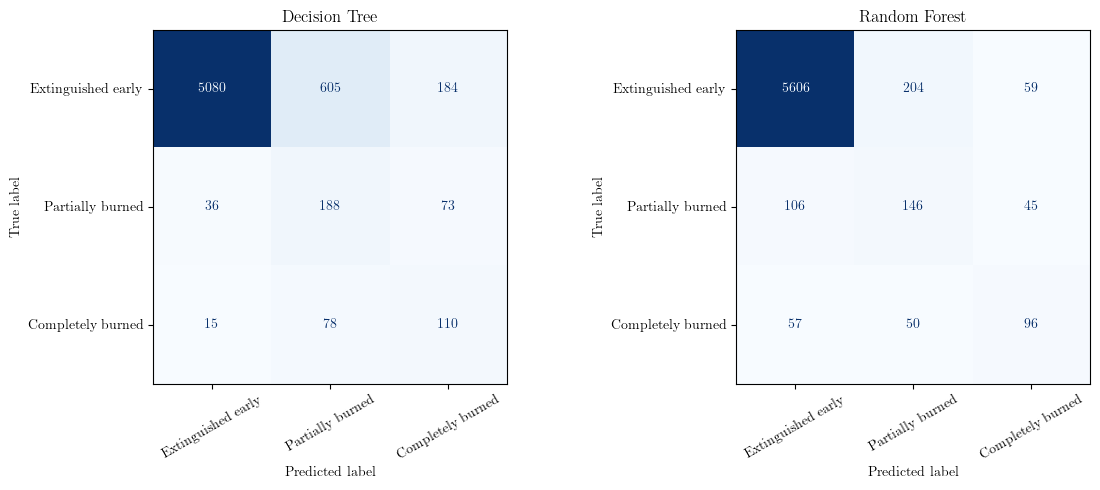

In [19]:
# 5c. confusion matrices
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=result_order)
    disp = ConfusionMatrixDisplay(cm, display_labels=result_order)
    disp.plot(ax=ax, colorbar=False, xticks_rotation=30, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

***6. Decision Tree Visualization***

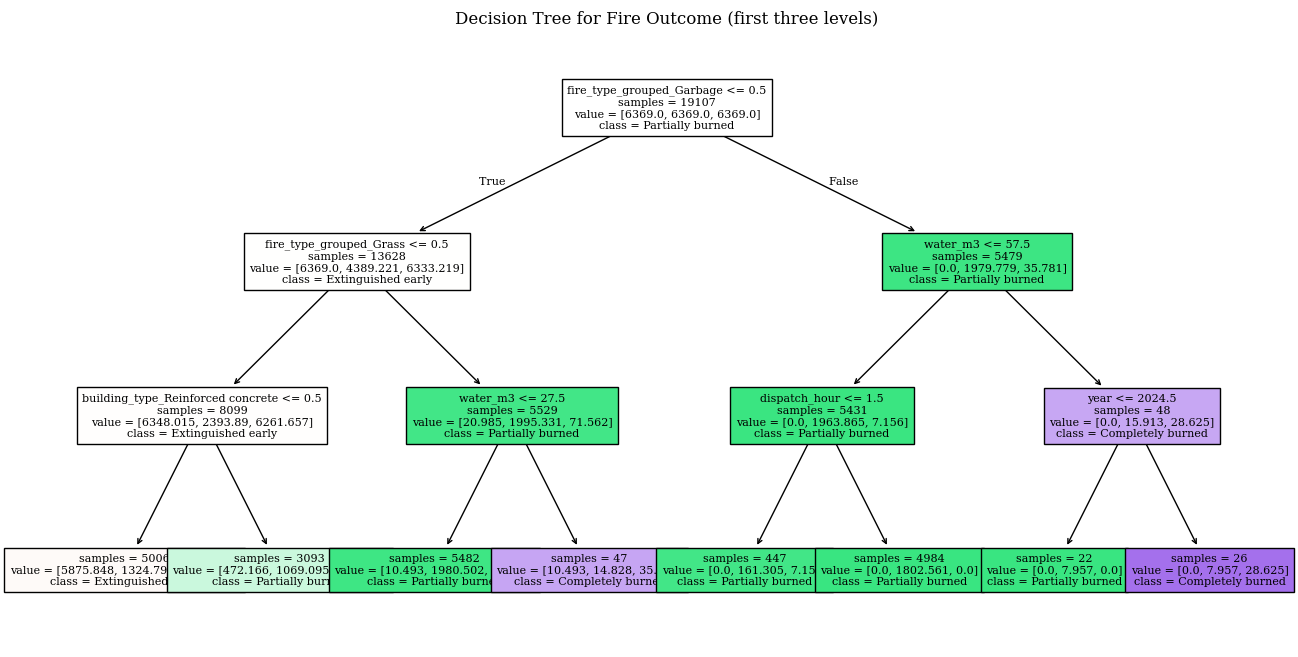

In [20]:
# 6a. shallow version of the tuned tree (max_depth=3), for a readable figure only -- the model
# actually evaluated above used best_depth, this is a separate, shallower tree fit purely for display
from sklearn.tree import plot_tree

plt.rcParams["text.usetex"] = False  # feature names contain "_", which LaTeX cannot print directly
dt_display = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)
dt_display.fit(X_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(dt_display, max_depth=3, feature_names=X.columns, class_names=result_order,
          filled=True, impurity=False, fontsize=8)
plt.title("Decision Tree for Fire Outcome (first three levels)")
plt.savefig("figures/dt_classification.png", dpi=300, bbox_inches="tight")
plt.show()
plt.rcParams["text.usetex"] = True